# Series de Fourier: magnitud y fase
**Bioseñales y sistemas — Bioingeniería, Universidad de Antioquia**

Integrantes: Valentina García Obando Cc 1000539432, Mariana Giraldo Gil  Cc 1062424194

En esta práctica se calculan los coeficientes de la serie de Fourier de señales periódicas con NumPy, se grafican sus espectros de magnitud y fase, se reconstruyen las señales con un número finito de armónicos (fenómeno de Gibbs) y se analiza el espectro de una señal ECG.

## Resumen

En esta práctica se aplicó la serie de Fourier al análisis espectral y la reconstrucción de señales periódicas usando Python y NumPy. Primero se construyeron una señal cuadrada y una triangular con la misma frecuencia fundamental (5 Hz), amplitud (1) y número de muestras (1000 por período), y se graficaron en el dominio del tiempo. Luego se implementó una función que calcula los coeficientes de la serie de Fourier en forma exponencial mediante la FFT, y otra que grafica los espectros de magnitud y fase. Los coeficientes obtenidos coincidieron con los valores teóricos: en ambas señales solo aparecen armónicos impares, con magnitudes que decaen como 1/k en la cuadrada y como 1/k² en la triangular.

Después se implementó una función de reconstrucción por suma de senos y se reconstruyeron ambas señales con 1, 3, 5, 20 y 50 armónicos. La señal triangular se recuperó casi por completo con solo 5 armónicos, mientras que la cuadrada presentó oscilaciones y un sobrepico cercano al 9 % de la altura del salto junto a cada discontinuidad, que no disminuye al aumentar el número de armónicos (fenómeno de Gibbs).

Finalmente se analizó un latido de ECG sintético sin ruido. Su espectro mostró que las ondas P y T, por ser lentas, se concentran en bajas frecuencias (por debajo de unos 10 a 15 Hz), mientras que el complejo QRS, por ser breve y abrupto, ocupa una banda más amplia, hasta unos 40 Hz. La reconstrucción progresiva confirmó que los primeros armónicos describen la morfología general del latido y los de mayor orden aportan los detalles del QRS.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## a) y b) Señales cuadrada y triangular

Se define un período de cada señal con los mismos parámetros: frecuencia fundamental f0 = 5 Hz, amplitud A = 1 y N = 1000 muestras por período. Se muestrea exactamente un período (sin repetir el punto final) porque así la FFT entrega directamente los coeficientes de la serie de Fourier.

In [2]:
# Parámetros comunes
f0 = 5          # frecuencia fundamental (Hz)
A = 1           # amplitud
N = 1000        # número de muestras en un período
T0 = 1 / f0     # período (s)

# Vector de tiempo: un período exacto, sin incluir t = T0
t = np.arange(N) * T0 / N

# a) Señal cuadrada: +A en la primera mitad del período, -A en la segunda
cuadrada = np.where(t < T0 / 2, A, -A)

# b) Señal triangular: misma f0, A y N
triangular = (2 * A / np.pi) * np.arcsin(np.sin(2 * np.pi * f0 * t))

## c) Señales en el dominio del tiempo

Se grafican 3 períodos de cada señal (repitiendo el período construido) para visualizar su periodicidad.

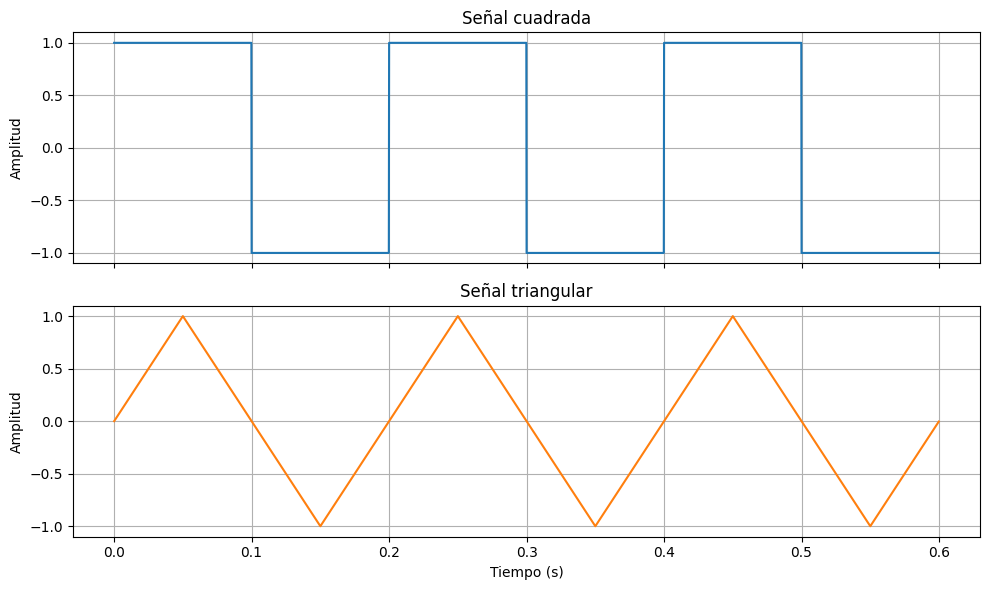

In [3]:
periodos = 3
t_plot = np.arange(N * periodos) * T0 / N

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].plot(t_plot, np.tile(cuadrada, periodos))
ax[0].set_title('Señal cuadrada')
ax[0].set_ylabel('Amplitud')
ax[0].grid(True)

ax[1].plot(t_plot, np.tile(triangular, periodos), color='tab:orange')
ax[1].set_title('Señal triangular')
ax[1].set_xlabel('Tiempo (s)')
ax[1].set_ylabel('Amplitud')
ax[1].grid(True)

plt.tight_layout()
plt.show()

## d) Función para calcular los coeficientes de Fourier

Como la señal contiene exactamente un período con N muestras, los coeficientes de la forma exponencial se obtienen con la FFT dividida entre N:

$$c_k = \frac{1}{N}\sum_{n=0}^{N-1} x[n]\,e^{-j2\pi kn/N}$$

La FFT devuelve los coeficientes en el orden k = 0, 1, 2, ..., y en la segunda mitad del arreglo quedan los armónicos negativos (c[-1] es el armónico k = -1).

In [4]:
def coeficientes_fourier(x):
    """Recibe un período de una señal y devuelve sus coeficientes c_k (forma exponencial)."""
    N = len(x)
    return np.fft.fft(x) / N

## e) Coeficientes de la señal cuadrada y la triangular

In [6]:
c_cuad = coeficientes_fourier(cuadrada)
c_tri = coeficientes_fourier(triangular)

print(' k   |c_k| cuadrada   |c_k| triangular')
for k in range(8):
    print(f'{k:2d}      {np.abs(c_cuad[k]):.4f}           {np.abs(c_tri[k]):.4f}')

 k   |c_k| cuadrada   |c_k| triangular
 0      0.0000           0.0000
 1      0.6366           0.4053
 2      0.0000           0.0000
 3      0.2122           0.0450
 4      0.0000           0.0000
 5      0.1273           0.0162
 6      0.0000           0.0000
 7      0.0910           0.0083


## f) Función para graficar los espectros de magnitud y fase

La función reordena los coeficientes para mostrar los armónicos desde -K hasta K. La fase de los coeficientes con magnitud prácticamente nula se fija en cero, porque en esos casos el ángulo solo refleja error numérico y no tiene significado.

In [7]:
def graficar_espectro(c, titulo, K=15):
    """Grafica magnitud y fase de los coeficientes c para los armónicos -K..K."""
    N = len(c)
    k = np.fft.fftshift(np.fft.fftfreq(N, 1 / N)).astype(int)  # índices de armónico
    c_ord = np.fft.fftshift(c)                                  # coeficientes ordenados

    sel = np.abs(k) <= K
    k, c_ord = k[sel], c_ord[sel]

    magnitud = np.abs(c_ord)
    fase = np.degrees(np.angle(c_ord))
    fase[magnitud < 1e-10] = 0      # se ignora la fase de coeficientes nulos

    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    ax[0].stem(k, magnitud, basefmt=' ')
    ax[0].set_title(f'Espectro de magnitud — {titulo}')
    ax[0].set_ylabel('|c_k|')
    ax[0].grid(True)

    ax[1].stem(k, fase, basefmt=' ')
    ax[1].set_title(f'Espectro de fase — {titulo}')
    ax[1].set_xlabel('Armónico k (frecuencia = k·f0)')
    ax[1].set_ylabel('Fase (grados)')
    ax[1].set_yticks([-180, -90, 0, 90, 180])
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()

## g) Espectros de la señal cuadrada y la triangular

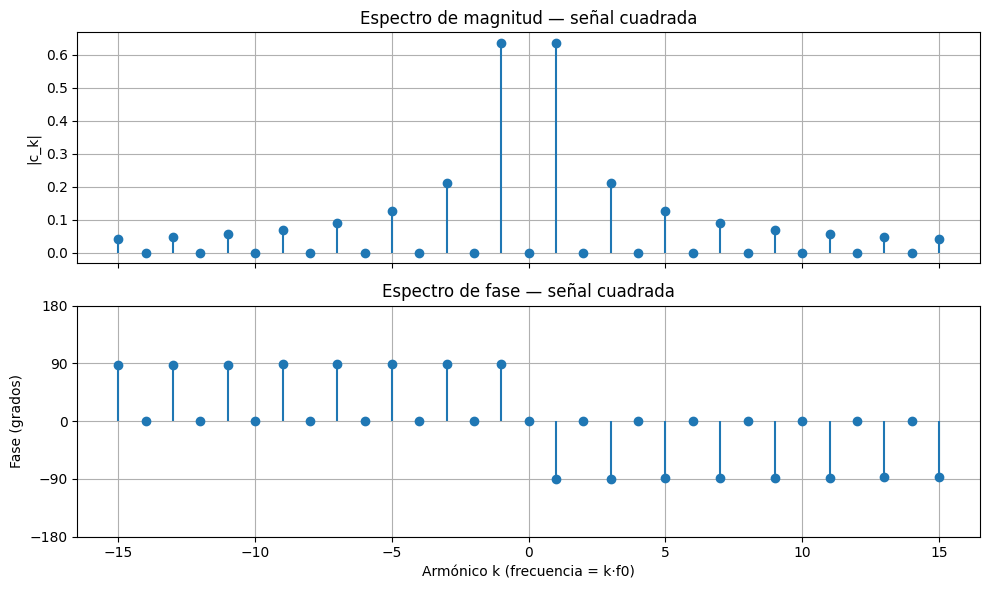

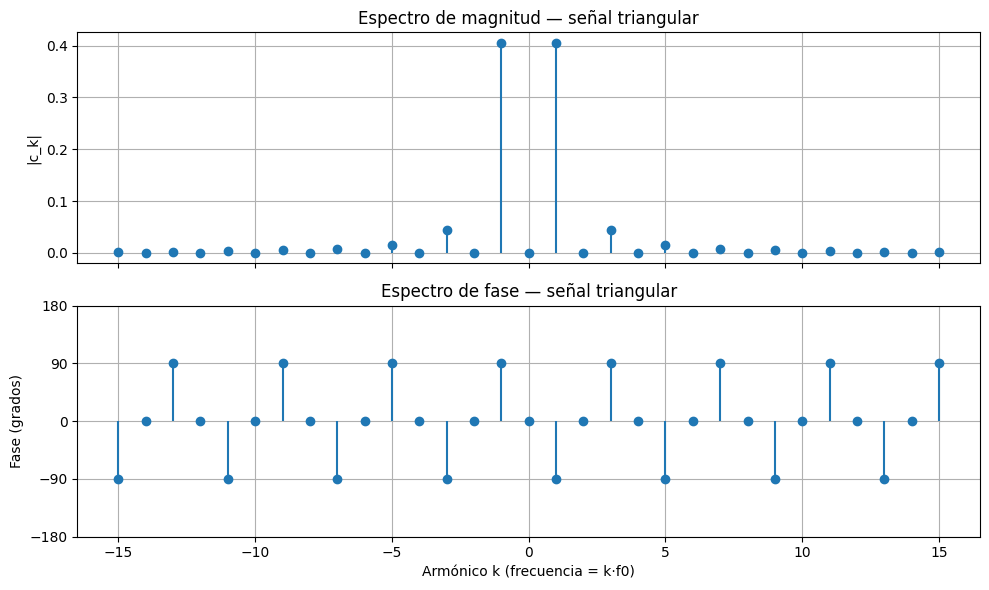

In [8]:
graficar_espectro(c_cuad, 'señal cuadrada')
graficar_espectro(c_tri, 'señal triangular')

**Análisis de los espectros**

- En ambas señales solo aparecen armónicos impares (k = ±1, ±3, ±5, ...) y el coeficiente c_0 es cero, porque las dos señales tienen valor medio nulo y simetría de media onda.
- El espectro de magnitud es simétrico respecto a k = 0 (|c_k| = |c_-k|) y el de fase es antisimétrico, como corresponde a señales reales.
- En la señal cuadrada la magnitud decae como 1/k (2A/πk), mientras que en la triangular decae como 1/k² (4A/π²k²). Por eso la triangular concentra casi toda su energía en el primer armónico: es una señal continua, sin saltos, y necesita menos contenido de alta frecuencia que la cuadrada, que tiene discontinuidades.
- La fase de los armónicos es de ±90°, lo que indica que ambas señales se componen únicamente de términos seno (simetría impar). En la cuadrada todos los armónicos positivos tienen fase de -90°; en la triangular la fase alterna entre -90° y +90°, es decir, los senos alternan de signo.

## h) Función de reconstrucción con suma de senos

Como la señal es real, cada par de coeficientes c_k y c_-k se combina en una sola sinusoide de amplitud 2|c_k| y fase arg(c_k). Escrita como seno:

$$x[n] \approx c_0 + \sum_{k=1}^{K} 2|c_k|\,\mathrm{sen}\!\left(\frac{2\pi kn}{N} + \arg(c_k) + \frac{\pi}{2}\right)$$

donde K es el número de armónicos usados en la reconstrucción.

In [9]:
def reconstruir(c, n_armonicos):
    """Reconstruye un período de la señal sumando los primeros n_armonicos senos."""
    N = len(c)
    n = np.arange(N)
    x_rec = np.full(N, c[0].real)            # componente DC (c_0)

    for k in range(1, n_armonicos + 1):
        amplitud = 2 * np.abs(c[k])
        fase = np.angle(c[k])
        x_rec = x_rec + amplitud * np.sin(2 * np.pi * k * n / N + fase + np.pi / 2)

    return x_rec

## i) Reconstrucción con N = 1, 3, 5, 20 y 50 armónicos

Se reconstruyen ambas señales incluyendo los armónicos desde k = 1 hasta k = N y se comparan con la señal original. Como los armónicos pares son nulos, solo los impares aportan a la suma.

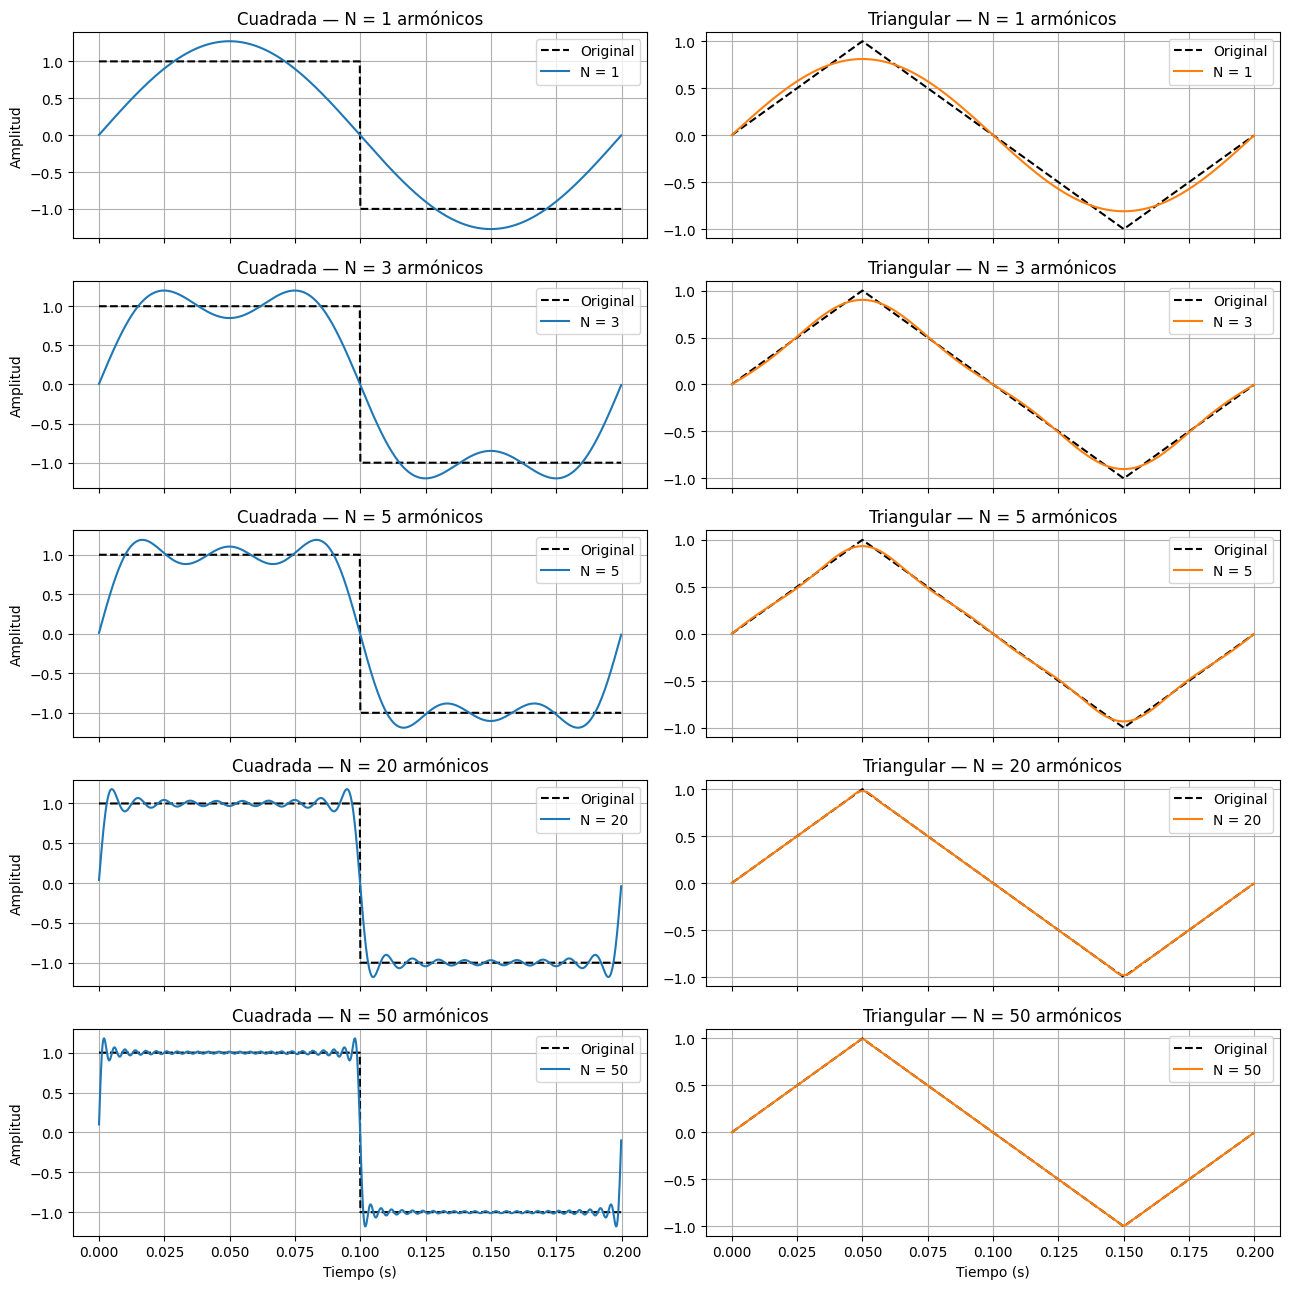

In [10]:
lista_armonicos = [1, 3, 5, 20, 50]

fig, ax = plt.subplots(len(lista_armonicos), 2, figsize=(13, 13), sharex=True)

for i, n_arm in enumerate(lista_armonicos):
    # Señal cuadrada (columna izquierda)
    ax[i, 0].plot(t, cuadrada, 'k--', label='Original')
    ax[i, 0].plot(t, reconstruir(c_cuad, n_arm), label=f'N = {n_arm}')
    ax[i, 0].set_title(f'Cuadrada — N = {n_arm} armónicos')
    ax[i, 0].set_ylabel('Amplitud')
    ax[i, 0].legend(loc='upper right')
    ax[i, 0].grid(True)

    # Señal triangular (columna derecha)
    ax[i, 1].plot(t, triangular, 'k--', label='Original')
    ax[i, 1].plot(t, reconstruir(c_tri, n_arm), color='tab:orange', label=f'N = {n_arm}')
    ax[i, 1].set_title(f'Triangular — N = {n_arm} armónicos')
    ax[i, 1].legend(loc='upper right')
    ax[i, 1].grid(True)

ax[-1, 0].set_xlabel('Tiempo (s)')
ax[-1, 1].set_xlabel('Tiempo (s)')
plt.tight_layout()
plt.show()

**Análisis de las reconstrucciones**

- Con N = 1 ambas reconstrucciones son un seno puro a la frecuencia fundamental (amplitud 4A/π ≈ 1.27 en la cuadrada y 8A/π² ≈ 0.81 en la triangular).
- La señal triangular se aproxima muy bien con pocos armónicos: con N = 5 ya es casi indistinguible de la original, y solo se nota un leve redondeo en los picos. Esto concuerda con su espectro, que decae como 1/k².
- La señal cuadrada converge mucho más lento. Al aumentar N los tramos planos se aplanan y los flancos se vuelven más verticales, pero aparecen oscilaciones cerca de los saltos y un sobrepico que no desaparece ni con N = 50 (fenómeno de Gibbs).

## j) Fenómeno de Gibbs

Para analizar el fenómeno se hace un acercamiento a la discontinuidad de la señal cuadrada en t = 0 y se mide el valor máximo de la reconstrucción para distintos números de armónicos.

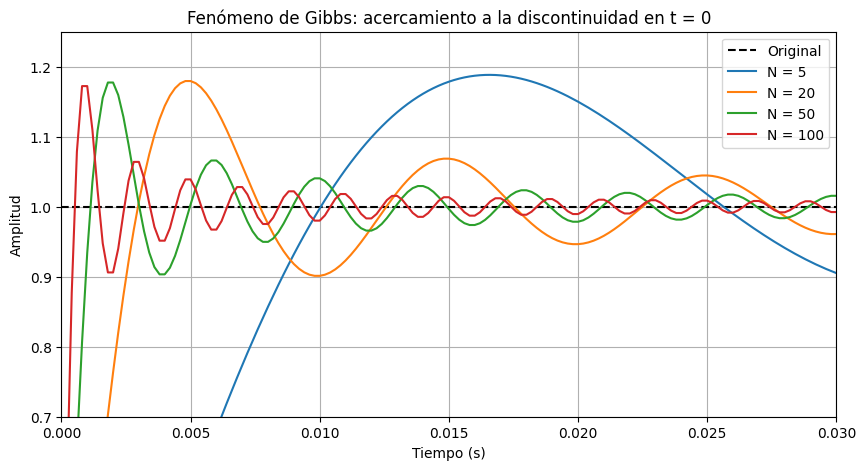

In [11]:
armonicos_gibbs = [5, 20, 50, 100]

plt.figure(figsize=(10, 5))
plt.plot(t, cuadrada, 'k--', label='Original')
for n_arm in armonicos_gibbs:
    plt.plot(t, reconstruir(c_cuad, n_arm), label=f'N = {n_arm}')

plt.xlim(0, 0.03)
plt.ylim(0.7, 1.25)
plt.title('Fenómeno de Gibbs: acercamiento a la discontinuidad en t = 0')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
salto = 2 * A   # altura de la discontinuidad (de -A a +A)

print('  N    Máximo    Sobrepico (% del salto)')
for n_arm in [1, 3, 5, 20, 50, 100]:
    maximo = reconstruir(c_cuad, n_arm).max()
    sobrepico = (maximo - A) / salto * 100
    print(f'{n_arm:4d}    {maximo:.4f}        {sobrepico:.2f} %')

  N    Máximo    Sobrepico (% del salto)
   1    1.2732        13.66 %
   3    1.2004        10.02 %
   5    1.1884        9.42 %
  20    1.1795        8.98 %
  50    1.1774        8.87 %
 100    1.1723        8.62 %


**Análisis del fenómeno de Gibbs**

El fenómeno de Gibbs aparece al aproximar una señal con discontinuidades mediante una suma finita de armónicos. Como cada armónico es una función continua y suave, la suma truncada no puede reproducir un salto instantáneo: en su lugar genera una transición de pendiente finita acompañada de oscilaciones a ambos lados de la discontinuidad.

En las reconstrucciones de la señal cuadrada se observa que:

- Al aumentar N, las oscilaciones se vuelven más rápidas y se concentran cada vez más cerca del salto, por lo que la aproximación mejora en los tramos planos.
- El sobrepico, en cambio, no disminuye: su valor máximo se estabiliza alrededor de 1.18, es decir, cerca del 9 % de la altura del salto, sin importar cuántos armónicos se usen. Solo se vuelve más angosto y se acerca a la discontinuidad.
- En el punto exacto del salto la reconstrucción pasa por el valor medio entre los dos niveles (cero).

Esto significa que la serie converge a la señal en energía (el error cuadrático medio tiende a cero al crecer N), pero no converge de manera uniforme cerca de la discontinuidad. La causa está en el espectro: los coeficientes de la señal cuadrada decaen lentamente (1/k), de modo que los armónicos que se descartan al truncar todavía tienen una amplitud apreciable. La señal triangular, que es continua y cuyos coeficientes decaen como 1/k², no presenta este fenómeno.

En la práctica el fenómeno de Gibbs es relevante en el procesamiento de bioseñales: al filtrar o truncar el espectro de una señal con cambios abruptos, como el complejo QRS del ECG, pueden aparecer oscilaciones artificiales (*ringing*) alrededor de esos cambios.

## k) Señal ECG y su composición espectral

Se utiliza un latido de ECG sintético sin ruido, modelado como la suma de ondas gaussianas que representan la onda P, el complejo QRS y la onda T. Se asume una frecuencia cardíaca de 60 lpm, de modo que el período es T0 = 1 s y la frecuencia fundamental es f0 = 1 Hz: así el armónico k corresponde directamente a k Hz. La frecuencia de muestreo es de 500 Hz.

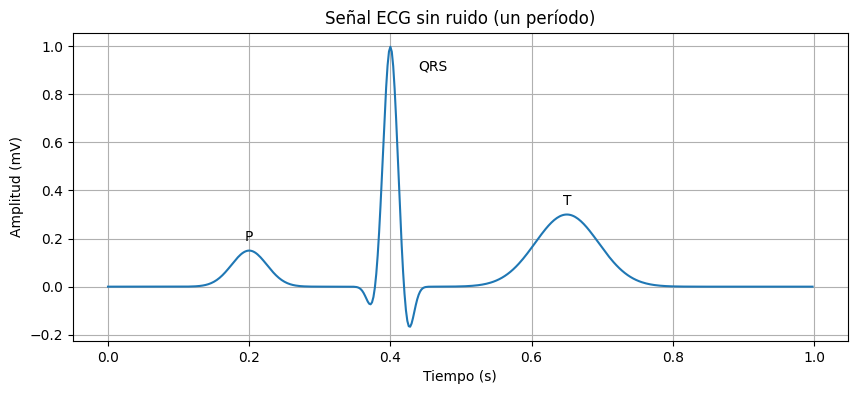

In [13]:
fs_ecg = 500                      # frecuencia de muestreo (Hz)
T0_ecg = 1.0                      # período de un latido (s) -> 60 lpm
N_ecg = int(fs_ecg * T0_ecg)      # muestras por período
t_ecg = np.arange(N_ecg) / fs_ecg

def onda(amplitud, centro, ancho):
    """Onda gaussiana: amplitud (mV), centro (s) y ancho (s)."""
    return amplitud * np.exp(-((t_ecg - centro) ** 2) / (2 * ancho ** 2))

onda_P = onda(0.15, 0.20, 0.025)
complejo_QRS = onda(-0.10, 0.375, 0.008) + onda(1.0, 0.40, 0.010) + onda(-0.20, 0.425, 0.008)
onda_T = onda(0.30, 0.65, 0.045)

ecg = onda_P + complejo_QRS + onda_T

plt.figure(figsize=(10, 4))
plt.plot(t_ecg, ecg)
plt.annotate('P', (0.20, 0.19), ha='center')
plt.annotate('QRS', (0.44, 0.9))
plt.annotate('T', (0.65, 0.34), ha='center')
plt.title('Señal ECG sin ruido (un período)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (mV)')
plt.grid(True)
plt.show()

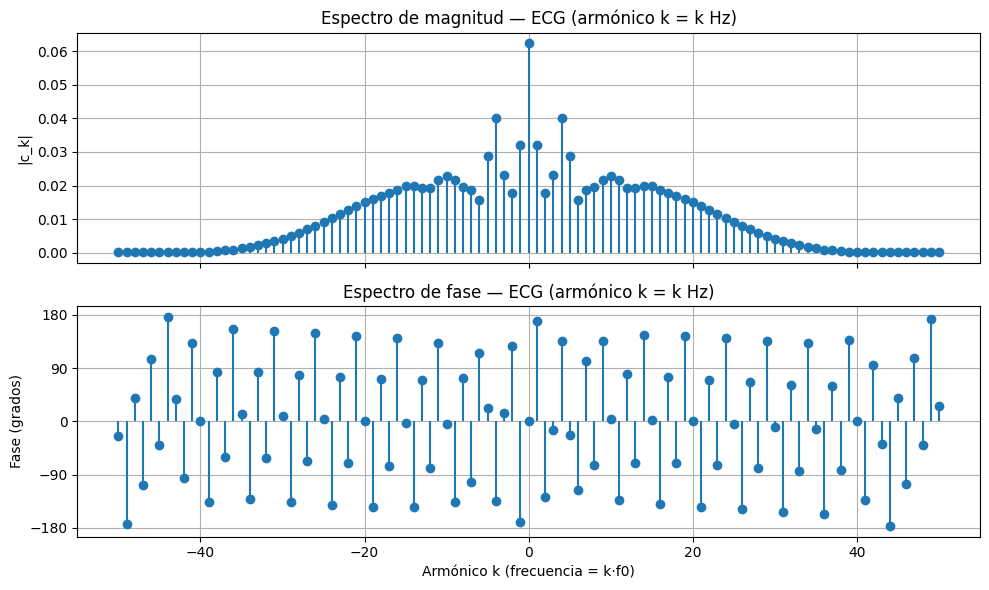

In [14]:
c_ecg = coeficientes_fourier(ecg)
graficar_espectro(c_ecg, 'ECG (armónico k = k Hz)', K=50)

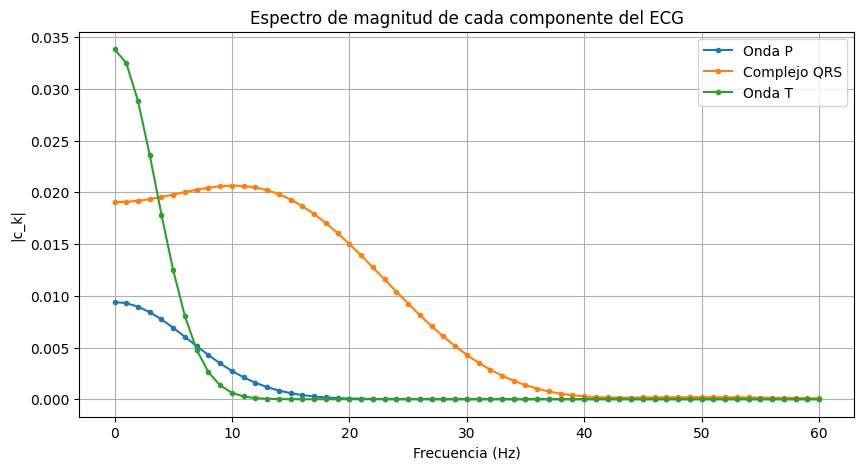

In [15]:
f = np.arange(61)   # 0 a 60 Hz (k = f porque f0 = 1 Hz)

plt.figure(figsize=(10, 5))
plt.plot(f, np.abs(coeficientes_fourier(onda_P))[:61], 'o-', ms=3, label='Onda P')
plt.plot(f, np.abs(coeficientes_fourier(complejo_QRS))[:61], 'o-', ms=3, label='Complejo QRS')
plt.plot(f, np.abs(coeficientes_fourier(onda_T))[:61], 'o-', ms=3, label='Onda T')
plt.title('Espectro de magnitud de cada componente del ECG')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('|c_k|')
plt.legend()
plt.grid(True)
plt.show()

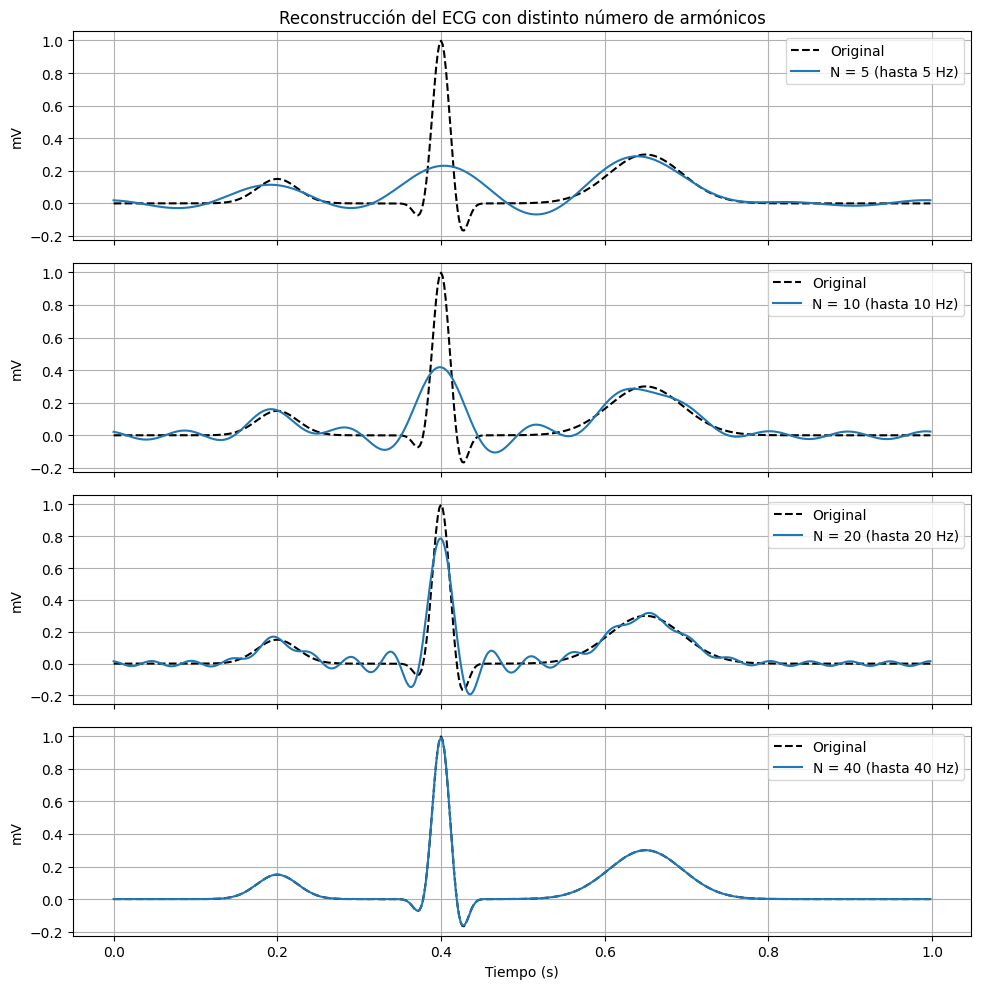

In [16]:
lista_ecg = [5, 10, 20, 40]

fig, ax = plt.subplots(len(lista_ecg), 1, figsize=(10, 10), sharex=True)
for i, n_arm in enumerate(lista_ecg):
    ax[i].plot(t_ecg, ecg, 'k--', label='Original')
    ax[i].plot(t_ecg, reconstruir(c_ecg, n_arm), label=f'N = {n_arm} (hasta {n_arm} Hz)')
    ax[i].set_ylabel('mV')
    ax[i].legend(loc='upper right')
    ax[i].grid(True)

ax[0].set_title('Reconstrucción del ECG con distinto número de armónicos')
ax[-1].set_xlabel('Tiempo (s)')
plt.tight_layout()
plt.show()

**Interpretación del espectro del ECG**

El espectro del ECG concentra la mayor parte de su energía en bajas frecuencias y decae progresivamente hasta hacerse despreciable alrededor de 40–50 Hz. Cada onda del ciclo cardíaco aporta en una banda distinta, según su duración: entre más corta y abrupta es la onda, más ancho es su espectro.

- **Onda P (despolarización auricular):** es una onda lenta y de baja amplitud. Su contenido espectral se ubica en bajas frecuencias, aproximadamente entre 0.5 y 10 Hz.
- **Onda T (repolarización ventricular):** es la onda más ancha y suave del ciclo, por lo que tiene el espectro más angosto, concentrado aproximadamente entre 0.5 y 7 Hz.
- **Complejo QRS (despolarización ventricular):** es el evento más rápido y de mayor amplitud. Su energía se distribuye en una banda mucho más amplia, aproximadamente entre 10 y 40 Hz, con el mayor aporte entre 10 y 25 Hz.

Esto se confirma en la reconstrucción: con solo 5 armónicos (hasta 5 Hz) ya aparece la forma general de las ondas P y T, pero el complejo QRS queda bajo y ensanchado; se necesitan alrededor de 40 armónicos para recuperar su amplitud y sus pendientes. Es decir, los primeros armónicos describen la morfología general del latido y los de mayor orden aportan los detalles finos del QRS.

Fisiológicamente, esto explica por qué un filtrado pasa-bajas demasiado agresivo reduce la amplitud del QRS y distorsiona su forma, y por qué el ancho de banda recomendado para un ECG diagnóstico es de aproximadamente 0.05 a 150 Hz.

*Nota: los rangos de frecuencia son valores típicos reportados en la literatura; la señal usada es sintética, por lo que sus bandas exactas dependen de los anchos elegidos para cada onda.*

En la señal analizada, por debajo de unos 5 Hz predomina la onda T, mientras que por encima de 10 Hz prácticamente todo el contenido espectral proviene del complejo QRS.

## Informe

### Fenómeno de Gibbs

Al reconstruir la señal cuadrada con un número finito de armónicos se observaron oscilaciones alrededor de cada discontinuidad y un sobrepico que no desaparece al aumentar N. Con N = 1 la reconstrucción es un seno de amplitud 1.27; a partir de N = 5 el valor máximo se estabiliza cerca de 1.18, lo que equivale a un sobrepico de aproximadamente el 9 % de la altura del salto. Al pasar de 20 a 50 y a 100 armónicos el sobrepico conserva su altura, pero se hace más angosto y se desplaza hacia la discontinuidad.

Este comportamiento se debe a que una suma finita de funciones continuas no puede representar un salto instantáneo. La serie converge en energía, pero no de forma uniforme en la vecindad de la discontinuidad. La comparación con la señal triangular lo evidencia: al ser continua, sus coeficientes decaen como 1/k² (frente a 1/k en la cuadrada) y con solo 5 armónicos la reconstrucción es casi idéntica a la original, sin sobrepico.

### Interpretación del espectro del ECG

El espectro del ECG analizado concentra su energía en bajas frecuencias y es despreciable por encima de 40–50 Hz. Al separar el aporte de cada onda se encontró que la onda T, la más lenta, se limita a frecuencias menores de unos 10 Hz; la onda P se extiende hasta unos 15 Hz; y el complejo QRS, el evento más breve y abrupto del ciclo, ocupa la banda más ancha, hasta unos 40 Hz. Esto refleja la relación inversa entre duración en el tiempo y ancho de banda en frecuencia.

La reconstrucción progresiva lo confirma: con 5 armónicos se recupera la forma de las ondas P y T, pero el QRS aparece atenuado y ensanchado; con 20 armónicos alcanza cerca del 80 % de su amplitud, con oscilaciones a su alrededor similares a las del fenómeno de Gibbs; y con 40 armónicos la reconstrucción coincide con la señal original. En términos fisiológicos, los armónicos bajos describen los procesos lentos (despolarización auricular y repolarización ventricular) y los armónicos altos la despolarización ventricular rápida. Por eso el filtrado de un ECG debe conservar un ancho de banda suficiente: recortar las frecuencias altas reduce la amplitud del QRS y puede introducir oscilaciones artificiales.

## Conclusiones

- La FFT de NumPy, aplicada a un período exacto de la señal y dividida entre N, entrega directamente los coeficientes de la serie de Fourier exponencial; los valores obtenidos coincidieron con los teóricos (2A/πk para la cuadrada y 4A/π²k² para la triangular).
- Los espectros de magnitud y fase resumen la estructura de la señal: la ausencia de armónicos pares refleja la simetría de media onda y las fases de ±90° indican que ambas señales se componen solo de términos seno.
- La rapidez con que decaen los coeficientes determina cuántos armónicos se necesitan para reconstruir una señal: las señales suaves requieren pocos, mientras que las que tienen cambios abruptos requieren muchos y presentan el fenómeno de Gibbs.
- En el ECG, cada onda ocupa una banda de frecuencia acorde con su duración, lo que permite relacionar el contenido espectral con los eventos fisiológicos del ciclo cardíaco y definir criterios de filtrado.

## Referencias

- NumPy. *numpy.fft: Discrete Fourier Transform*. https://numpy.org/doc/stable/reference/routines.fft.html
- Malmivuo, J. & Plonsey, R. *Bioelectromagnetism*. Oxford University Press, 1995.
- Oppenheim, A. V. & Willsky, A. S. *Señales y sistemas*, 2.ª ed. Prentice Hall, 1998.